# Lecture 9: Overconfident Households and Income Risk

**Lecture 9 of 9** · [Series index](README.md)

*This lecture builds on [Lecture 5: A Two-Asset HANK Economy](05_two_asset_hank.ipynb) and [Lecture 7: Bayesian Updating and Overconfidence](07_bayesian_overconfidence.ipynb). The series begins with [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb), which adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). The Newton solver used elsewhere in the series is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0. This lecture is shared under the same licence.*

## Overview

In [Lecture 5](05_two_asset_hank.ipynb), what made marginal propensities to consume high was a household's distance from its borrowing limit, and households chose that distance by weighing the return on saving against the risk of a run of bad income draws. That trade-off depends on how risky households **think** their income is.

This lecture asks what happens when households are overprecise about their own future: they believe their income is less volatile than it is. It is the same distortion as in [Lecture 7](07_bayesian_overconfidence.ipynb), a perceived precision $\kappa$ times the true one, applied to the innovations in household income.

The plan is:

1. how to model misperceived income risk, and what the evidence says,
2. **precautionary saving in closed form**, in a two-period model with CARA utility, where precautionary saving is proportional to perceived risk,
3. the infinite-horizon household problem with a borrowing limit, solved by the endogenous grid method with **two transition matrices**: a perceived one for decisions and the true one for the evolution of the population,
4. **general equilibrium**: an Aiyagari economy in which overprecision lowers wealth, raises the interest rate and puts more households at the borrowing limit,
5. **MPCs** and **welfare**: who ends up with high MPCs, and who pays for the mistake, and
6. **intertemporal MPCs** and the **intertemporal Keynesian cross**: how overprecision changes the output response to a deficit-financed transfer, with the Jacobian computed by forward-mode automatic differentiation.

To keep the mechanism visible, the household holds a single liquid asset. [Lecture 5](05_two_asset_hank.ipynb) shows how much an illiquid asset adds; the exercises suggest how to combine the two.

## Perceived and actual income risk

### The income process

Household $i$'s labour productivity $e_{it}$ follows

$$
\log e_{i,t+1} = \rho \log e_{it} + \sigma\, \varepsilon_{i,t+1}, \qquad \varepsilon \sim N(0, 1)
$$

with $\rho = 0.9$ and $\sigma = 0.2$ at an annual frequency, as in Lecture 5.

### Overprecision about income

An overprecise household believes the innovations are less dispersed than they are:

$$
\hat\sigma^2 = \frac{\sigma^2}{\kappa}, \qquad \kappa > 1
$$

It knows the persistence $\rho$ and the current state $e_{it}$, so its **forecast** of next year's log income is correct. It is only too sure of that forecast. This is exactly overprecision in the sense of Lecture 7: the household's predictive intervals are too narrow, by the factor $1/\sqrt{\kappa}$.

Two assumptions are worth stating.

- **No learning.** The household keeps its belief even though its realised income keeps surprising it. Learning a variance takes many observations, and Lecture 7 showed that asymmetric updating can sustain miscalibration indefinitely. But this is a modelling choice, and it means we compare steady states with fixed beliefs.
- **The household is not overconfident about its level.** An overestimation version, in which households expect their income to be higher than it will be, would add a wealth effect on top. Keeping the mean correct isolates the effect of perceived risk.

### What the evidence says

Survey data that ask people for the probability distribution of their future income make it possible to compare perceived and realised risk (Dominitz and Manski, 1997; Manski, 2004). Pistaferri (2001) used Italian survey expectations to separate transitory from permanent income shocks. Rozsypal and Schlafmann (2023) find that households systematically **overestimate the persistence** of their income shocks, which makes low-income households too pessimistic and high-income households too optimistic.

The evidence on the **size** of perceived risk is less settled than the calibration evidence of Lecture 7, and it differs across groups. So this lecture treats $\kappa$ as a parameter and shows both directions: overprecision ($\kappa > 1$) and its opposite ($\kappa < 1$).

## Precautionary saving in closed form

Before solving the full model, a two-period example shows exactly how perceived risk enters saving.

### A two-period CARA model

A household has income $y_0$ today and uncertain income $y_1 \sim N(\mu_y, \sigma_y^2)$ tomorrow. It saves $s$ at interest rate $r$ and has CARA utility $u(c) = -e^{-\gamma c}/\gamma$, with absolute risk aversion $\gamma$:

$$
\max_s\; u(y_0 - s) + \beta\, \mathbb{E}\, u\big(y_1 + (1+r)s\big)
$$

The Euler equation is $e^{-\gamma(y_0 - s)} = \beta(1+r)\, \mathbb{E}\, e^{-\gamma(y_1 + (1+r)s)}$. For normal $y_1$, $\mathbb{E}\, e^{-\gamma y_1} = e^{-\gamma\mu_y + \gamma^2\sigma_y^2/2}$, so taking logs,

$$
-\gamma(y_0 - s) = \log\big(\beta(1+r)\big) - \gamma\big(\mu_y + (1+r)s\big) + \frac{\gamma^2 \sigma_y^2}{2}
$$

Solving for $s$:

$$
s^* = \underbrace{\frac{1}{2+r}\left[(y_0 - \mu_y) + \frac{\log\big(\beta(1+r)\big)}{\gamma}\right]}_{\text{smoothing and impatience}}
\;+\; \underbrace{\frac{\gamma\, \sigma_y^2}{2(2+r)}}_{\text{precautionary saving}}
$$

**Proposition 1 (precautionary saving).** Saving is the certainty-equivalent amount plus a precautionary term proportional to the variance the household **perceives**. A household with perceived variance $\hat\sigma_y^2 = \sigma_y^2/\kappa$ saves

$$
\boxed{\; s(\kappa) = s^* - \frac{\gamma\, \sigma_y^2}{2(2+r)}\left(1 - \frac{1}{\kappa}\right)\;}
$$

so it does only a fraction $1/\kappa$ of the precautionary saving it should.

**Proposition 2 (the cost).** Let $U(s)$ be expected utility under the **true** distribution. $U$ is maximised at $s^*$, so by a second-order expansion

$$
U(s^*) - U(s(\kappa)) \approx \tfrac{1}{2}\, |U''(s^*)|\, \big(s(\kappa) - s^*\big)^2 \;\propto\; \left(1 - \frac{1}{\kappa}\right)^2 \sigma_y^4
$$

The cost is second order in the saving error, as in Lectures 7 and 8, but the saving error itself is proportional to the variance of income. So the cost rises with the **fourth power** of income risk: overprecision is almost harmless when income is safe and costly when it is risky.

The code checks both propositions against a direct numerical maximisation of true expected utility.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax.scipy.stats import norm
from scipy.optimize import brentq, minimize_scalar
import matplotlib.pyplot as plt
from typing import NamedTuple

jax.config.update("jax_enable_x64", True)

In [2]:
def cara_saving(kappa, y0=1.0, mu_y=1.0, sigma_y=0.3, gamma=2.0, beta=0.96, r=0.04):
    # closed form (Proposition 1)
    return ((y0 - mu_y) + np.log(beta * (1 + r)) / gamma) / (2 + r) + gamma * sigma_y ** 2 / kappa / (2 * (2 + r))


def true_expected_utility(s, y0=1.0, mu_y=1.0, sigma_y=0.3, gamma=2.0, beta=0.96, r=0.04):
    u0 = -np.exp(-gamma * (y0 - s)) / gamma
    Eu1 = -np.exp(-gamma * (mu_y + (1 + r) * s) + gamma ** 2 * sigma_y ** 2 / 2) / gamma
    return u0 + beta * Eu1


for sigma_y in [0.2, 0.4]:
    s_num = minimize_scalar(lambda s: -true_expected_utility(s, sigma_y=sigma_y), bounds=(-1, 1), method='bounded',
                            options=dict(xatol=1e-12)).x
    print(f'sigma_y = {sigma_y}: optimal saving, closed form {cara_saving(1.0, sigma_y=sigma_y):.6f}, numerical {s_num:.6f}')
    for kappa in [2.0, 4.0]:
        s_k = cara_saving(kappa, sigma_y=sigma_y)
        loss = true_expected_utility(s_num, sigma_y=sigma_y) - true_expected_utility(s_k, sigma_y=sigma_y)
        scale = (1 - 1 / kappa) ** 2 * sigma_y ** 4
        print(f'   kappa = {kappa}: saving {s_k:.6f}, utility loss {loss:.3e}, loss / [(1 - 1/kappa)^2 sigma^4] = {loss / scale:.5f}')

sigma_y = 0.2: optimal saving, closed form 0.019215, numerical 0.019215
   kappa = 2.0: saving 0.009411, utility loss 2.758e-05, loss / [(1 - 1/kappa)^2 sigma^4] = 0.06896
   kappa = 4.0: saving 0.004509, utility loss 6.207e-05, loss / [(1 - 1/kappa)^2 sigma^4] = 0.06897
sigma_y = 0.4: optimal saving, closed form 0.078039, numerical 0.078039
   kappa = 2.0: saving 0.038823, utility loss 4.971e-04, loss / [(1 - 1/kappa)^2 sigma^4] = 0.07767
   kappa = 4.0: saving 0.019215, utility loss 1.120e-03, loss / [(1 - 1/kappa)^2 sigma^4] = 0.07776


The closed form matches the numerical optimum, and the loss divided by $(1 - 1/\kappa)^2\sigma_y^4$ is close to constant across $\kappa$ and across levels of risk, as Proposition 2 says.

CARA utility is convenient because precautionary saving doesn't depend on wealth. With CRRA utility, prudence falls with wealth, and with a borrowing limit, households close to the limit save for a second reason: to avoid hitting it. The infinite-horizon model needs to be solved numerically, but the logic is the same. What drives the buffer stock is perceived risk.

## The household problem

### The Bellman equation

A household with assets $a$ and productivity $e$ earns $w e$ and receives $(1+r)a$. It chooses consumption and next year's assets subject to a borrowing limit at zero:

$$
V(e, a) = \max_{c,\, a'} \; \frac{c^{1-\gamma}}{1-\gamma} + \beta\, \hat{\mathbb{E}}\left[V(e', a') \mid e\right]
\quad \text{s.t.} \quad c + a' = (1+r) a + w e, \qquad a' \geq 0
$$

The hat on the expectation is the only change from the standard model: the household takes expectations with its **perceived** transition probabilities $\hat\Pi(e, e')$.

### The Euler equation and the endogenous grid method

Wherever the borrowing limit doesn't bind, the Euler equation is

$$
c^{-\gamma} = \beta (1+r)\, \sum_{e'} \hat\Pi(e, e')\, c'(e', a')^{-\gamma}
$$

The endogenous grid method (Carroll, 2006) inverts this directly:

1. on a grid of next-period assets $a'$, compute expected marginal utility using $\hat\Pi$,
2. invert to find the consumption $c = \big[\beta(1+r)\hat{\mathbb{E}}\,c'^{-\gamma}\big]^{-1/\gamma}$ that makes each $a'$ optimal,
3. recover the cash on hand $c + a'$ at which that choice is made, and interpolate back to the asset grid,
4. where cash on hand is below the smallest value on the endogenous grid, the household is at the limit: $a' = 0$ and it consumes everything.

Iterating to a fixed point gives the stationary policies. This is the same method as the household block of Lecture 5, with one asset instead of two.

### Two transition matrices

Decisions use $\hat\Pi$, but the population moves according to the **true** $\Pi$. The stationary distribution $D(e, a)$ is the fixed point of

$$
D'(e', a') = \sum_e \Pi(e, e') \sum_a D(e, a)\, \mathbf{1}\{\text{policy sends } a \text{ to } a'\}
$$

with the policy spread over the two nearest grid points (Young's 2010 lottery method), exactly as in Lecture 5. This split between a perceived model for choices and a true model for outcomes is the general recipe for putting non-rational beliefs into heterogeneous-agent models.

### Discretising both processes on one grid

For the comparison to be clean, $\hat\Pi$ and $\Pi$ must live on the same productivity grid, and $\kappa = 1$ must reproduce the truth exactly. So we fix a grid of 41 points spanning $\pm 3$ unconditional standard deviations of the true process, and compute both matrices by Tauchen's method on that grid: $\Pi$ with $\sigma$, $\hat\Pi$ with $\hat\sigma = \sigma/\sqrt\kappa$. Productivity is normalised to have mean one under the true stationary distribution.

In [3]:
def agrid(amax, n, amin=0.0):
    # Grid with points concentrated near the lower bound (as in Lecture 5).
    pivot = abs(amin) + 0.25
    g = np.geomspace(amin + pivot, amax + pivot, n) - pivot
    g[0] = amin
    return g


def tauchen_on_grid(x, rho, sigma):
    # Transition probabilities of log e' = rho log e + sigma eps on a fixed grid x (midpoint bins).
    mid = (x[1:] + x[:-1]) / 2
    cdf = norm.cdf((mid[None, :] - rho * x[:, None]) / sigma)
    cdf = jnp.concatenate([jnp.zeros((len(x), 1)), cdf, jnp.ones((len(x), 1))], axis=1)
    return np.asarray(jnp.diff(cdf, axis=1))


def stationary_probs(Pi):
    pi = np.ones(len(Pi)) / len(Pi)
    for _ in range(100_000):
        pn = pi @ Pi
        if np.max(np.abs(pn - pi)) < 1e-15:
            break
        pi = pn
    return pi


class Income(NamedTuple):
    x: np.ndarray       # log productivity grid
    e: np.ndarray       # productivity, mean one under the true process
    Pi: np.ndarray      # true transitions
    pi: np.ndarray      # true stationary distribution
    rho: float
    sigma: float


def get_income(rho=0.9, sigma=0.2, n=41, width=3.0):
    sd = sigma / np.sqrt(1 - rho ** 2)
    x = np.linspace(-width * sd, width * sd, n)
    Pi = tauchen_on_grid(x, rho, sigma)
    pi = stationary_probs(Pi)
    return Income(x, np.exp(x) / (pi @ np.exp(x)), Pi, pi, rho, sigma)


def perceived_Pi(kappa, inc):
    return tauchen_on_grid(inc.x, inc.rho, inc.sigma / np.sqrt(kappa))


inc = get_income()
mid = len(inc.x) // 2
interior = np.abs(inc.x) < 1.5 * inc.sigma / np.sqrt(1 - inc.rho ** 2)
for kappa in [1.0, 4.0]:
    P_hat = perceived_Pi(kappa, inc)
    log_mean = P_hat @ inc.x
    log_sd = np.sqrt(P_hat @ inc.x ** 2 - log_mean ** 2)
    gap = np.max(np.abs(log_mean - inc.Pi @ inc.x)[interior])
    print(f'kappa = {kappa}: sd of next year log income at median e = {log_sd[mid]:.4f} '
          f'(target sigma/sqrt(kappa) = {inc.sigma / np.sqrt(kappa):.4f}); '
          f'largest forecast difference from the truth within 1.5 sd: {gap:.1e}')

kappa = 1.0: sd of next year log income at median e = 0.2010 (target sigma/sqrt(kappa) = 0.2000); largest forecast difference from the truth within 1.5 sd: 0.0e+00
kappa = 4.0: sd of next year log income at median e = 0.1020 (target sigma/sqrt(kappa) = 0.1000); largest forecast difference from the truth within 1.5 sd: 3.3e-06


Away from the edges of the grid, both matrices give the same forecast of log income, and the conditional standard deviations are within a few percent of their targets. The grid has to be fine: with $\kappa = 4$ the perceived innovations have a standard deviation of 0.1, and a grid much coarser than that can't represent them. The household block follows.

In [4]:
class HH(NamedTuple):
    a_grid: jnp.ndarray
    e: jnp.ndarray
    Pi_hat: jnp.ndarray       # perceived transitions, used for decisions
    beta: float
    gamma: float
    r: float
    w: float


def egm_step(c_next, P):
    # One backward step of the endogenous grid method, given next period's consumption policy c_next (e', a').
    ag = P.a_grid
    W = P.beta * (1 + P.r) * P.Pi_hat @ c_next ** (-P.gamma)           # perceived expected marginal value of a'
    c_endo = W ** (-1 / P.gamma)                                       # consumption that makes each a' optimal
    coh_endo = c_endo + ag[None, :]                                    # the cash on hand at which it does
    coh = (1 + P.r) * ag[None, :] + P.w * P.e[:, None]
    ap = jax.vmap(jnp.interp)(coh, coh_endo, jnp.broadcast_to(ag, coh_endo.shape))
    ap = jnp.maximum(ap, ag[0])                                        # borrowing limit
    return coh - ap, ap


@jax.jit
def solve_policies(P, tol=1e-12, maxit=20_000):
    c0 = 0.1 * ((1 + P.r) * P.a_grid[None, :] + P.w * P.e[:, None])

    def cond(st):
        return (st[2] > tol) & (st[3] < maxit)

    def body(st):
        c, _, _, it = st
        c_new, ap = egm_step(c, P)
        return c_new, ap, jnp.max(jnp.abs(c_new - c)), it + 1

    c, ap, err, it = jax.lax.while_loop(cond, body, (c0, jnp.zeros_like(c0), 1.0, 0))
    return c, ap, err, it


def lottery(x, grid):
    # Lower bracket index and the weight on it (Young's method).
    j = jnp.clip(jnp.searchsorted(grid, x, side='right') - 1, 0, grid.shape[0] - 2)
    wgt = (grid[j + 1] - x) / (grid[j + 1] - grid[j])
    return j, jnp.clip(wgt, 0.0, 1.0)


def forward(D, ap, a_grid, Pi_true):
    # One period of the distribution: move assets by the policy, productivity by the TRUE process.
    nE = ap.shape[0]
    j, wgt = lottery(ap, a_grid)
    ei = jnp.broadcast_to(jnp.arange(nE)[:, None], ap.shape)
    Dn = jnp.zeros_like(D).at[ei, j].add(D * wgt).at[ei, j + 1].add(D * (1 - wgt))
    return Pi_true.T @ Dn


@jax.jit
def stationary_distribution(ap, a_grid, Pi_true, tol=1e-13, maxit=100_000):
    D0 = jnp.ones(ap.shape) / ap.size

    def cond(st):
        return (st[1] > tol) & (st[2] < maxit)

    def body(st):
        D, _, it = st
        Dn = forward(D, ap, a_grid, Pi_true)
        return Dn, jnp.max(jnp.abs(Dn - D)), it + 1

    D, err, it = jax.lax.while_loop(cond, body, (D0, 1.0, 0))
    return D, err

## General equilibrium

### Firms and markets

A representative firm rents capital $K$ and effective labour $L$ at rates $r + \delta$ and $w$, with technology $Y = K^\alpha L^{1-\alpha}$. Effective labour is $L = \sum e\, \pi(e) = 1$, because productivity has mean one under the true process. The firm's first-order conditions give capital demand and the wage as functions of the interest rate:

$$
K(r) = \left(\frac{r + \delta}{\alpha}\right)^{\frac{1}{\alpha - 1}}, \qquad w(r) = (1-\alpha) K(r)^\alpha
$$

Households own the capital stock, so the asset market clears when household wealth equals capital demand:

$$
\mathcal{A}(r; \kappa) \equiv \sum_{e, a} D(e, a)\, a'(e, a) = K(r)
$$

This is Aiyagari's (1994) economy. We calibrate $\beta$ so that the Bayesian economy ($\kappa = 1$) has $r = 4\%$, with $\gamma = 2$, $\alpha = 0.33$ and $\delta = 0.06$, and keep $\beta$ fixed as $\kappa$ changes.

The market-clearing condition is one equation in one unknown, $r$. Newton's method would need the derivative of household wealth with respect to $r$, which means differentiating through two loops that run until convergence; with a single unknown it is simpler to bracket the root and use Brent's method.

In [5]:
class Economy(NamedTuple):
    alpha: float
    delta: float
    gamma: float
    a_grid: jnp.ndarray


def capital_demand(r, ec):
    K = ((r + ec.delta) / ec.alpha) ** (1 / (ec.alpha - 1))
    return K, (1 - ec.alpha) * K ** ec.alpha


def household(r, kappa, beta, ec, inc):
    K, w = capital_demand(r, ec)
    P = HH(ec.a_grid, jnp.asarray(inc.e), jnp.asarray(perceived_Pi(kappa, inc)), beta, ec.gamma, r, w)
    c, ap, err, it = solve_policies(P)
    D, derr = stationary_distribution(ap, ec.a_grid, jnp.asarray(inc.Pi))
    return dict(c=np.asarray(c), ap=np.asarray(ap), D=np.asarray(D), A=float(jnp.sum(D * ap)), K=K, w=w, r=r,
                kappa=kappa, beta=beta, P=P, policy_err=float(err), dist_err=float(derr))


def excess_wealth(r, kappa, beta, ec, inc):
    return household(r, kappa, beta, ec, inc)['A'] - capital_demand(r, ec)[0]


def equilibrium(kappa, beta, ec, inc):
    r = brentq(lambda r_: excess_wealth(r_, kappa, beta, ec, inc), 0.0, 1 / beta - 1 - 1e-6, xtol=1e-13)
    return household(r, kappa, beta, ec, inc)


ec = Economy(alpha=0.33, delta=0.06, gamma=2.0, a_grid=jnp.asarray(agrid(200, 400)))
beta = brentq(lambda b: excess_wealth(0.04, 1.0, b, ec, inc), 0.90, 0.97, xtol=1e-13)
print(f'beta = {beta:.6f}')

beta = 0.944415


In [6]:
def mpcs(h):
    # Annual MPC out of a small windfall: finite difference of consumption in assets.
    ag = np.asarray(h['P'].a_grid)
    dc = np.diff(h['c'], axis=1) / ((1 + h['r']) * np.diff(ag)[None, :])
    return np.concatenate([dc, dc[:, -1:]], axis=1)


def euler_errors(h):
    # log10 relative Euler errors at unconstrained points with mass, using the PERCEIVED expectation.
    P = h['P']
    ag, c, ap, D = np.asarray(P.a_grid), h['c'], h['ap'], h['D']
    c_next = np.stack([np.interp(ap[i], ag, c[j]) for j in range(c.shape[0]) for i in range(c.shape[0])])
    c_next = c_next.reshape(c.shape[0], c.shape[0], -1)               # [e', e, a]
    Emu = np.einsum('ij,jia->ia', np.asarray(P.Pi_hat), c_next ** (-P.gamma))
    err = np.abs((P.beta * (1 + P.r) * Emu) ** (-1 / P.gamma) / c - 1)
    mask = (ap > 1e-8) & (D > 1e-10) & (ap < ag[-1] * 0.9)
    return np.log10(np.average(err[mask], weights=D[mask])), np.log10(err[mask].max())


def summary(h):
    m = mpcs(h)
    D = h['D']
    constrained = h['ap'] <= 1e-10
    y = h['K'] ** ec.alpha
    return dict(r=100 * h['r'], K=h['K'], w=h['w'], KY=h['K'] / y, constrained=100 * D[constrained].sum(),
                mpc=np.sum(D * m), mpc_con=np.sum(D * m * constrained) / max(D[constrained].sum(), 1e-12))


kappas = [0.5, 1.0, 2.0, 4.0]
eq = {kap: equilibrium(kap, beta, ec, inc) for kap in kappas}
print(f"{'kappa':>6} {'r (%)':>7} {'K':>7} {'K/Y':>6} {'wage':>7} {'at limit (%)':>13} {'mean MPC':>9} {'MPC at limit':>13}")
for kap, h in eq.items():
    s_ = summary(h)
    print(f"{kap:6.1f} {s_['r']:7.3f} {s_['K']:7.3f} {s_['KY']:6.2f} {s_['w']:7.4f} {s_['constrained']:13.1f} "
          f"{s_['mpc']:9.3f} {s_['mpc_con']:13.3f}")
mean_err, max_err = euler_errors(eq[4.0])
print(f'\nEuler equation errors at kappa = 4 (log10): mean {mean_err:.1f}, max {max_err:.1f};  '
      f'max mass at top of asset grid: {max(h["D"][:, -1].sum() for h in eq.values()):.1e}')

 kappa   r (%)       K    K/Y    wage  at limit (%)  mean MPC  MPC at limit
   0.5   3.695   6.223   3.40  1.2249           0.5     0.088         0.979
   1.0   4.000   5.942   3.30  1.2063           2.9     0.112         0.991
   2.0   4.213   5.757   3.23  1.1939           7.3     0.153         0.995
   4.0   4.325   5.665   3.20  1.1875          11.6     0.190         0.993

Euler equation errors at kappa = 4 (log10): mean -7.6, max -5.9;  max mass at top of asset grid: 1.4e-27


### Reading the table

- **Less wealth, higher interest rates.** Overprecise households hold smaller buffer stocks at every interest rate. To clear the asset market with less household wealth, the interest rate has to rise, which reduces capital demand and raises the return on saving until households hold the smaller capital stock willingly. With $\kappa = 4$, $r$ rises by about a third of a percentage point and capital falls by about 5%.
- **Lower wages.** Less capital per worker means lower wages, a general-equilibrium cost that falls on everyone, including households who are not near the limit.
- **More households at the limit, higher MPCs.** The share of households with no assets roughly quadruples, and the mean MPC rises by about 70%. Underconfidence ($\kappa = 0.5$) does the reverse.

The one-asset model is known to produce too few constrained households and MPCs that are low relative to the evidence (Kaplan and Violante, 2014); that was one of the reasons for Lecture 5. Overprecision is a second way to raise MPCs in a one-asset model: not by locking wealth away, but by making households hold too little of it.

The figure shows the Aiyagari diagram, household wealth against capital demand, and the wealth distributions.

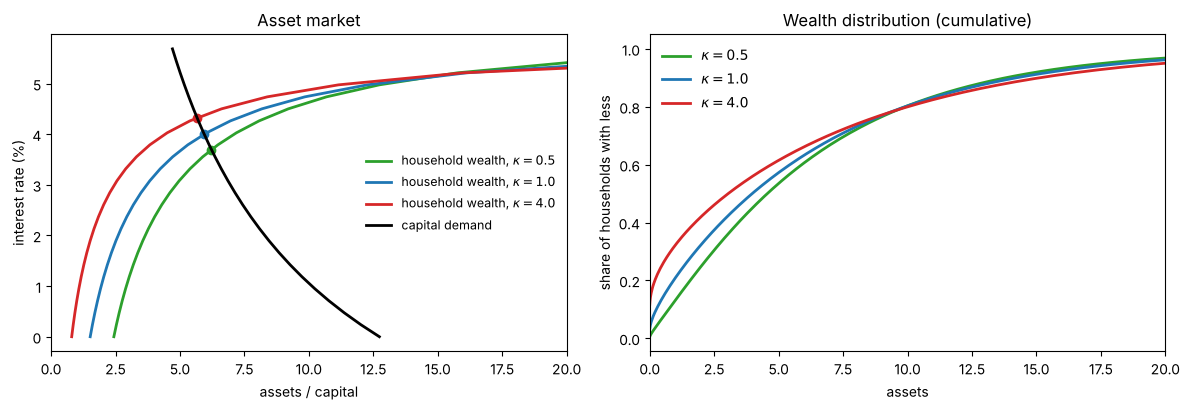

In [7]:
r_grid = np.linspace(0.0, 1 / beta - 1 - 0.002, 25)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
colors = {0.5: 'C2', 1.0: 'C0', 2.0: 'C1', 4.0: 'C3'}
for kap in [0.5, 1.0, 4.0]:
    A_supply = [household(r_, kap, beta, ec, inc)['A'] for r_ in r_grid]
    axes[0].plot(A_supply, 100 * r_grid, color=colors[kap], lw=2, label=rf'household wealth, $\kappa = {kap}$')
    axes[0].plot(eq[kap]['K'], 100 * eq[kap]['r'], 'o', color=colors[kap])
axes[0].plot([capital_demand(r_, ec)[0] for r_ in r_grid], 100 * r_grid, 'k', lw=2, label='capital demand')
axes[0].set_xlim(0, 20)
axes[0].set_xlabel('assets / capital')
axes[0].set_ylabel('interest rate (%)')
axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title('Asset market')

ag = np.asarray(ec.a_grid)
for kap in [0.5, 1.0, 4.0]:
    D_a = eq[kap]['D'].sum(axis=0)
    axes[1].plot(ag, np.cumsum(D_a), color=colors[kap], lw=2, label=rf'$\kappa = {kap}$')
axes[1].set_xlim(0, 20)
axes[1].set_xlabel('assets')
axes[1].set_ylabel('share of households with less')
axes[1].set_title('Wealth distribution (cumulative)')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## Who has high MPCs, and who pays

### MPCs across the distribution

An MPC is high when the borrowing limit binds or is close to binding. The overprecise household's buffer stock is smaller relative to its income at every point in the distribution, so more households sit close to the limit after a run of bad draws, and they stay there longer, because they don't rebuild buffers as quickly.

The next figure shows the consumption functions and MPCs for a low-productivity and a median-productivity household, at each economy's equilibrium prices.

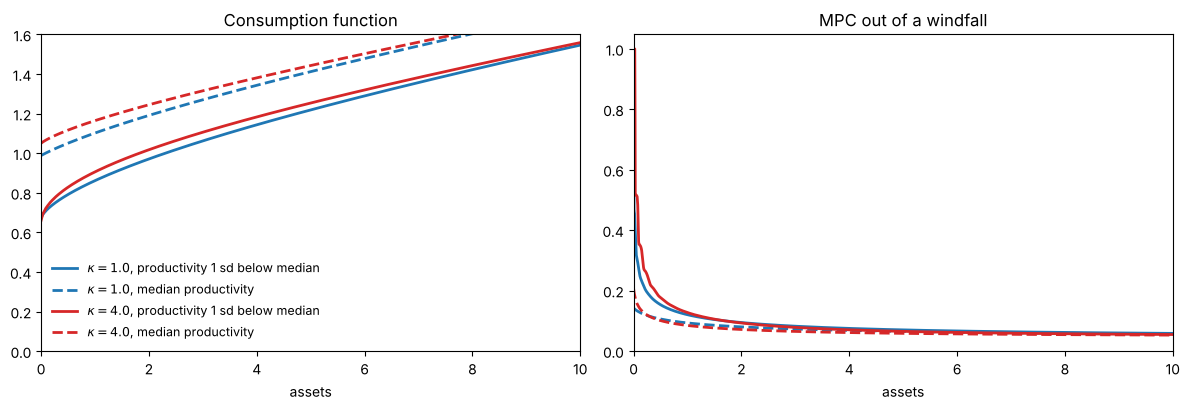

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ag = np.asarray(ec.a_grid)
for kap in [1.0, 4.0]:
    h = eq[kap]
    m = mpcs(h)
    for ie, ls in [(mid - 7, '-'), (mid, '--')]:
        lab = rf'$\kappa = {kap}$, ' + ('productivity 1 sd below median' if ie < mid else 'median productivity')
        axes[0].plot(ag, h['c'][ie], color=colors[kap], ls=ls, lw=2, label=lab)
        axes[1].plot(ag, m[ie], color=colors[kap], ls=ls, lw=2, label=lab)
axes[0].set_xlim(0, 10); axes[0].set_ylim(0, 1.6)
axes[0].set_title('Consumption function')
axes[1].set_xlim(0, 10)
axes[1].set_title('MPC out of a windfall')
for ax in axes:
    ax.set_xlabel('assets')
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

At the same assets and productivity, the overprecise household consumes more. Its MPC is higher at low wealth: with a smaller buffer target, it plans to run its assets down towards the limit, where extra cash is spent rather than saved. Once wealth reaches a couple of years of income, the two MPCs converge.

### The welfare cost

The household's choices are optimal under its beliefs but not under the truth. To measure the cost, evaluate each policy under the **true** process. Given policies $c(e, a)$ and $a'(e, a)$, the value of following them forever is the fixed point of

$$
V^{\text{true}}(e, a) = \frac{c(e, a)^{1-\gamma}}{1-\gamma} + \beta \sum_{e'} \Pi(e, e')\, V^{\text{true}}\big(e', a'(e, a)\big)
$$

which is the Bellman equation without the max, with $\Pi$ in place of $\hat\Pi$. Because utility is CRRA, scaling consumption in every state by $1 + \lambda$ scales $V$ by $(1+\lambda)^{1-\gamma}$, so the **consumption-equivalent** loss of following the overprecise policy is

$$
1 + \lambda(e, a) = \left(\frac{V^{\text{true}}_\kappa(e, a)}{V^{\text{true}}_1(e, a)}\right)^{\frac{1}{1-\gamma}}
$$

We compute it in two ways:

- **at the same prices**, the partial-equilibrium cost of the mistake, holding $r$ and $w$ at the Bayesian equilibrium, and
- **across steady states**, the overprecise economy at its own equilibrium prices against the Bayesian economy at its own, which adds the effect of lower wages and higher interest rates. This compares steady states and ignores the transition between them.

In [9]:
def true_value(h, Pi_true, tol=1e-11):
    P = h['P']
    c, ap = jnp.asarray(h['c']), jnp.asarray(h['ap'])
    j, wgt = lottery(ap, P.a_grid)
    u = c ** (1 - P.gamma) / (1 - P.gamma)
    Pi_t = jnp.asarray(Pi_true)

    def body(st):
        V, _, it = st
        EV = Pi_t @ V
        V_new = u + P.beta * (jnp.take_along_axis(EV, j, 1) * wgt + jnp.take_along_axis(EV, j + 1, 1) * (1 - wgt))
        return V_new, jnp.max(jnp.abs(V_new - V)), it + 1

    V, err, it = jax.lax.while_loop(lambda st: (st[1] > tol) & (st[2] < 200_000), body, (u / (1 - P.beta), 1.0, 0))
    return np.asarray(V)


def ce_loss(V_k, V_1, gamma):
    # consumption-equivalent loss, % (positive = worse off)
    return -100 * ((V_k / V_1) ** (1 / (1 - gamma)) - 1)


h1 = eq[1.0]
V1 = true_value(h1, inc.Pi)
D1 = h1['D']
print(f"{'':10s}{'same prices':>14s}{'':>27s}{'across steady states':>22s}")
print(f"{'kappa':>6} {'mean':>9} {'poorest, a = 0':>16} {'median e, a = 0':>16} {'mean':>14}")
for kap in [0.5, 2.0, 4.0]:
    h_pe = household(h1['r'], kap, beta, ec, inc)                    # Bayesian prices
    loss_pe = ce_loss(true_value(h_pe, inc.Pi), V1, ec.gamma)
    loss_ge = ce_loss(true_value(eq[kap], inc.Pi), V1, ec.gamma)
    print(f'{kap:6.1f} {np.sum(D1 * loss_pe):9.3f} {loss_pe[0, 0]:16.3f} {loss_pe[mid, 0]:16.3f} '
          f'{np.sum(D1 * loss_ge):14.3f}')
print('\nlosses in % of consumption in every period and state; averages weight states by the Bayesian distribution')

             same prices                             across steady states
 kappa      mean   poorest, a = 0  median e, a = 0           mean


   0.5     0.181            0.173            0.392         -0.157


   2.0     0.116            0.051            0.195          0.290


   4.0     0.293            0.111            0.450          0.523

losses in % of consumption in every period and state; averages weight states by the Bayesian distribution


At the same prices, the cost of overprecision is a few tenths of a percent of consumption on average, much larger than the second-order costs of the overconfident firm, because income risk is large and the cost rises with the fourth power of risk (Proposition 2). It is largest for households near the limit with median productivity: they have the most to lose from a bad draw, and their mistake is to hold almost no buffer. The poorest households lose less, because with very low income they are at the limit anyway.

Across steady states, the cost of overprecision is larger again: lower wages and less capital add to the direct cost of under-saving, and the higher interest rate only partly offsets it for households with wealth. For underconfidence ($\kappa = 0.5$) the steady-state comparison goes the other way, because the economy ends up with more capital and higher wages. That comparison leaves out the consumption given up during the transition to build that capital, so it overstates the gain; it is a reminder that steady-state welfare comparisons in Aiyagari economies need care.

## Intertemporal MPCs and the Keynesian cross

### The intertemporal MPC matrix

[Lecture 5](05_two_asset_hank.ipynb) computed the household block's Jacobian with the fake-news algorithm. In a one-asset model with a short horizon, there is a more direct route: **forward-mode automatic differentiation** through the backward and forward iterations.

Let $C_t(\{z_s\})$ be aggregate consumption at date $t$ when labour income in every state is scaled by $1 + z_s$ at date $s$, starting from the stationary distribution, with households anticipating the whole path. The **intertemporal MPC matrix** is

$$
M_{t,s} = \frac{1}{w}\frac{\partial C_t}{\partial z_s}\bigg|_{z = 0}
$$

the response of consumption at $t$ to one unit of extra aggregate labour income at $s$ (Auclert, Rognlie and Straub, 2018). Column $s$ is the consumption response to news, at date $0$, of extra income at date $s$. Forward-mode differentiation computes one column per pass, so the whole $T \times T$ matrix takes $T$ passes, which JAX vectorises.

Two checks on $M$:

- **Budget.** Each household's extra income is eventually spent, so the present value of each column should be one dollar at the date the income arrives: $\sum_t (1+r)^{-(t-s)} M_{t,s} \approx 1$, up to truncation at $T$.
- **Finite differences.** A column computed by perturbing $z_s$ by a small amount should agree with autodiff.

In [10]:
T = 100


def make_consumption_path(h, inc):
    P = h['P']
    c_ss, D_ss = jnp.asarray(h['c']), jnp.asarray(h['D'])
    Pi_t = jnp.asarray(inc.Pi)

    def C_path(z):
        # backward: policies at each date given the anticipated income path (perceived expectations)
        def back(c_next, z_t):
            c, ap = egm_step(c_next, P._replace(w=P.w * (1 + z_t)))
            return c, (c, ap)
        _, (cs, aps) = jax.lax.scan(back, c_ss, z, reverse=True)

        # forward: the true population, starting from the stationary distribution
        def fwd(D, pol):
            c, ap = pol
            return forward(D, ap, P.a_grid, Pi_t), jnp.sum(D * c)
        _, C = jax.lax.scan(fwd, D_ss, (cs, aps))
        return C

    return jax.jit(C_path)


M = {}
for kap in [1.0, 4.0]:
    h = eq[kap]
    C_path = make_consumption_path(h, inc)
    M[kap] = np.asarray(jax.jacfwd(C_path)(jnp.zeros(T))) / h['w']
    disc = (1 + h['r']) ** -np.arange(T)
    z = np.zeros(T); z[3] = 1e-6
    fd = (np.asarray(C_path(jnp.asarray(z))) - np.asarray(C_path(jnp.zeros(T)))) / 1e-6 / h['w']
    print(f'kappa = {kap}: M[0,0] = {M[kap][0, 0]:.3f}, PV of column 0 = {disc @ M[kap][:, 0]:.4f}, '
          f'PV of column 10 = {(1 + h['r']) ** 10 * disc @ M[kap][:, 10]:.4f}, '
          f'autodiff vs finite difference (column 3): {np.max(np.abs(fd - M[kap][:, 3])):.1e}')

kappa = 1.0: M[0,0] = 0.086, PV of column 0 = 0.9987, PV of column 10 = 0.9984, autodiff vs finite difference (column 3): 2.0e-08


kappa = 4.0: M[0,0] = 0.133, PV of column 0 = 0.9984, PV of column 10 = 0.9981, autodiff vs finite difference (column 3): 5.6e-08


### The intertemporal Keynesian cross

Suppose prices are sticky enough that output is determined by demand, and monetary policy holds the real interest rate at its steady-state level. Changes in output accrue to households as labour income, in proportion to productivity. The government sends households a transfer $dT^{\text{r}}$ at date $0$, financed by issuing debt, and repays the debt with taxes $dT^{\text{x}}_t$ that are levied later:

$$
B_t = (1+r)B_{t-1} + dT^{\text{r}}_t - dT^{\text{x}}_t, \qquad dT^{\text{x}}_t = (r + 0.1)\, B_{t-1}
$$

so debt is paid down at 10% a year. Output equals consumption demand, and consumption responds to after-tax income through $M$:

$$
dY = M\left(dY + dT^{\text{r}} - dT^{\text{x}}\right)
\quad\Longrightarrow\quad
\boxed{\;dY = (I - M)^{-1} M\, \big(dT^{\text{r}} - dT^{\text{x}}\big)\;}
$$

This is the **intertemporal Keynesian cross** of Auclert, Rognlie and Straub (2018). The matrix $(I - M)^{-1}$ is the multiplier: extra spending is income to someone else, who spends part of it, now and later. Everything about households enters through $M$, so overprecision changes the multiplier only by changing the intertemporal MPCs.

kappa = 1.0: output response per dollar of transfer, year 0: 0.048, years 0-4: 0.138
kappa = 4.0: output response per dollar of transfer, year 0: 0.102, years 0-4: 0.163


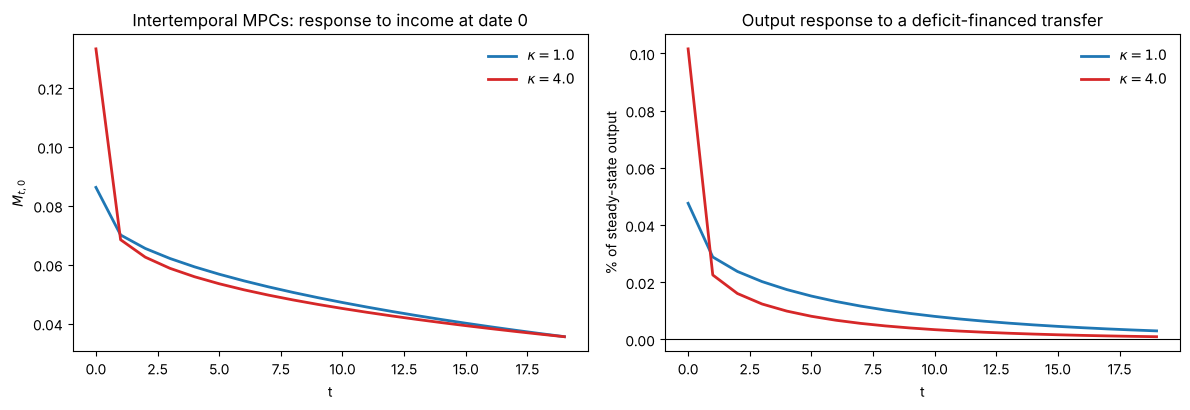

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
H = 20
for kap in [1.0, 4.0]:
    h = eq[kap]
    r = h['r']
    Y = h['K'] ** ec.alpha
    transfer = np.zeros(T); transfer[0] = 0.01 * Y                     # 1% of output, sent at date 0
    B, tax = np.zeros(T), np.zeros(T)
    for t_ in range(T):
        B_prev = B[t_ - 1] if t_ > 0 else 0.0
        tax[t_] = (r + 0.1) * B_prev
        B[t_] = (1 + r) * B_prev + transfer[t_] - tax[t_]
    dY = np.linalg.solve(np.eye(T) - M[kap], M[kap] @ (transfer - tax))
    axes[0].plot(np.arange(H), M[kap][:H, 0], color=colors[kap], lw=2, label=rf'$\kappa = {kap}$')
    axes[1].plot(np.arange(H), 100 * dY[:H] / Y, color=colors[kap], lw=2, label=rf'$\kappa = {kap}$')
    print(f'kappa = {kap}: output response per dollar of transfer, year 0: {dY[0] / transfer[0]:.3f}, '
          f'years 0-4: {dY[:5].sum() / transfer[0]:.3f}')
axes[0].set_title('Intertemporal MPCs: response to income at date 0')
axes[0].set_ylabel(r'$M_{t,0}$')
axes[1].set_title('Output response to a deficit-financed transfer')
axes[1].set_ylabel('% of steady-state output')
axes[1].axhline(0, color='k', lw=0.8)
for ax in axes:
    ax.set_xlabel('t')
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Overprecise households spend more of a windfall in the first year and less later, so the first column of $M$ is more front-loaded. The Keynesian cross amplifies this: the output response in the year of the transfer is much larger in the overprecise economy. Later, when taxes are levied to repay the debt, the same high MPCs make the tax bite harder, and output falls back faster, below the Bayesian economy's path.

The policy lesson is about **timing**. Households who under-save are more responsive to stimulus, so a given transfer has a larger short-run effect. But they are also more responsive to the taxes that pay for it, so the effect is more concentrated in the short run.

## Summary

| | Bayesian ($\kappa = 1$) | Overprecise ($\kappa = 4$) |
|---|---|---|
| Precautionary saving | as risk requires | a fraction $1/\kappa$ of it (two-period CARA) |
| Interest rate, capital, wages | baseline | higher $r$, less capital, lower wages |
| Households at the limit, mean MPC | baseline | about four times as many constrained; MPC up by about 70% |
| Welfare | baseline | a few tenths of a percent of consumption, largest near the limit |
| Transfer multiplier | baseline | larger on impact, more front-loaded |

Across the three overconfidence lectures (Lectures 7–9), the same parameter $\kappa$ has done three different things. In an asset market it created trade and reversals. In a firm it created an investment boom and bust. In households facing income risk it shrank buffer stocks, raised MPCs and changed how fiscal policy works. In each case Bayes' rule defines the benchmark, and the effect of the bias depends on where in the economy it sits.

## Exercises

1. **Overpersistence.** Rozsypal and Schlafmann (2023) find that households overestimate $\rho$ rather than misperceive $\sigma$. Replace $\hat\Pi$ with Tauchen's method using $\hat\rho > \rho$ and the true $\sigma$. Which households now under-save and which over-save? What happens to the mean MPC?
2. **The fourth power.** Re-solve the partial-equilibrium welfare cost with $\sigma = 0.1$ and $\sigma = 0.3$, holding $\kappa = 4$. Does the cost scale roughly with $\sigma^4$, as Proposition 2 suggests? Why might the borrowing limit change the answer?
3. **Learning.** Suppose households estimate $\sigma^2$ from their own past income changes, but discount negative surprises as in the asymmetric updating of Lecture 7. Simulate a cohort. Does perceived risk converge to the truth?
4. **Two assets.** In Lecture 5, illiquid saving acted as a commitment device. Would overprecise households hold more or less of their wealth in the illiquid asset? Sketch how to change `hh_step` to use $\hat\Pi$, and predict the effect on the share of wealthy hand-to-mouth households.
5. **Transfers to the poor.** Repeat the Keynesian cross exercise with a transfer of equal size to every household, rather than proportional to productivity. You will need a second Jacobian, for a lump-sum transfer. Does targeting matter more in the overprecise economy?

## References

- Aiyagari, S. R. (1994). Uninsured idiosyncratic risk and aggregate saving. *Quarterly Journal of Economics*, 109(3), 659–684.
- Auclert, A., Rognlie, M. and Straub, L. (2018). The intertemporal Keynesian cross. NBER Working Paper 25020.
- Carroll, C. D. (2006). The method of endogenous gridpoints for solving dynamic stochastic optimization problems. *Economics Letters*, 91(3), 312–320.
- Dominitz, J. and Manski, C. F. (1997). Using expectations data to study subjective income expectations. *Journal of the American Statistical Association*, 92(439), 855–867.
- Kaplan, G. and Violante, G. L. (2014). A model of the consumption response to fiscal stimulus payments. *Econometrica*, 82(4), 1199–1239.
- Kimball, M. S. (1990). Precautionary saving in the small and in the large. *Econometrica*, 58(1), 53–73.
- Manski, C. F. (2004). Measuring expectations. *Econometrica*, 72(5), 1329–1376.
- Pistaferri, L. (2001). Superior information, income shocks, and the permanent income hypothesis. *Review of Economics and Statistics*, 83(3), 465–476.
- Rozsypal, F. and Schlafmann, K. (2023). Overpersistence bias in individual income expectations and its aggregate implications. *American Economic Journal: Macroeconomics*, 15(4), 331–371.
- Tauchen, G. (1986). Finite state Markov-chain approximations to univariate and vector autoregressions. *Economics Letters*, 20(2), 177–181.
- Young, E. R. (2010). Solving the incomplete markets model with aggregate uncertainty using the Krusell–Smith algorithm and non-stochastic simulations. *Journal of Economic Dynamics and Control*, 34(1), 36–41.